In [ ]:
# Wilson-Cowan model

import os
import sys
import numpy as np

# Add the project root to the Python PATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '../../models/model_pet_nmda_WC'))
sys.path.append(project_root)

from src.data import load_and_preprocess_data as get_data
from src.models import simulate_wc
import time
import matplotlib.pyplot as plt
import os
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
np.set_printoptions(threshold=np.inf)


def plot_n_areas_wc(rE_store, rI_store, area_names, dt_store, sim_time, store_time,
                    xlim, ylim=None,
                    target_area_names=('Vis_9', 'Vis_5', 'Cont_PFCl_1', 'Default_PFC_7'),
                    names_for_figures=None,
                    labels=('E', 'I'),
                    colors=('#56c68a', '#eaa8b7'),
                    t_shift=2.0,
                    plot_I=False,
                    title=None, save_path=None, downsample=10,
                    legend=True, show=False):
    """
    Plot the firing rates of selected areas as separate small figures,
    matching the style of the Wong-Wang model's plot_n_areas.

    rE_store, rI_store : (N, T) arrays from simulate_wc.
    t_shift            : seconds subtracted from the time axis so the cue onset
                         sits at t=0 (Wong-Wang uses stim_start_time = 2).
    plot_I             : if False (default), only the E population is plotted;
                         if True, the I population is overlaid as a second curve.
    """

    mpl.rcParams.update({
        "font.size": 10, "axes.labelsize": 9, "axes.titlesize": 10,
        "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
        "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
        "xtick.major.size": 3, "ytick.major.size": 3,
    })

    # Time axis for the stored window, then shift so the cue onset is at 0
    T = rE_store.shape[1]
    t = (sim_time - store_time) + np.arange(T) * dt_store
    t_down = t[::downsample]

    # Which populations to draw: E only by default, E+I if plot_I
    pops = [(labels[0], rE_store, colors[0])]
    if plot_I:
        pops.append((labels[1], rI_store, colors[1]))

    lines = []

    for i, area_name in enumerate(target_area_names):
        fig, ax = plt.subplots(figsize=(1.65, 1.55))

        area_idx = np.where(np.array(area_names) == area_name)[0][0]

        for lab, store, color in pops:
            data = store[area_idx, ::downsample]
            line, = ax.plot(t_down - t_shift, data, label=f'${lab}$',
                            color=color, linewidth=2)
            if i == 0:
                lines.append(line)

        if i == 0 and legend:
            ax.legend(loc='upper right')

        name = names_for_figures[i] if names_for_figures is not None else area_name
        ax.set_title(name)
        ax.set_xlim(*xlim)
        if ylim:
            ax.set_ylim(*ylim)

        ax.set_ylabel('Activity (a.u.)')  # WC rates are normalized, not Hz
        ax.set_xlabel('Time (s)')
        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.grid(linestyle=':', alpha=0.5)

        if title:
            fig.suptitle(title, fontweight='bold')
        fig.tight_layout()

        if save_path:
            base, ext = os.path.splitext(save_path)
            fig.savefig(f"{base}_{area_name}{ext or '.png'}")
        if show:
            plt.show()
        plt.close(fig)

    return lines


def plot_traces_grid(rE_store, rI_store, dt_store, sim_time, store_time,
                     node_idx=None, ncols=10, area_names=None,
                     stim_window=None, title=None, save_path=None, dpi=100):
    """
    Plot one small panel per node in a grid, each showing that node's E and I
    traces over the whole simulation. Meant for quick visual inspection.

    Parameters
    ----------
    rE_store, rI_store : ndarray, shape (N, T)
        Stored excitatory / inhibitory firing rates (output of simulate_wc).
    dt_store : float
        Storage time step, in seconds (used to build the time axis).
    sim_time, store_time : float
        Total simulation time and stored duration, in seconds.
    node_idx : array-like of int, optional
        Which nodes to plot (one panel each). Default: first 100 nodes.
    ncols : int
        Number of columns in the panel grid (default 10 -> 10x10 for 100 nodes).
    area_names : array-like of str, optional
        Node names, used as small panel titles.
    stim_window : tuple (start, end), optional
        Cue window (s), shaded in every panel.
    title : str, optional
        Overall figure title.
    save_path : str, optional
        If given, the figure is saved there.
    dpi : int
        Figure resolution. Kept low on purpose so a big grid stays displayable.

    Returns
    -------
    fig, axes : the Matplotlib figure and the flattened array of axes.
    """
    N, T = rE_store.shape

    # Absolute time axis for the stored window
    t = (sim_time - store_time) + np.arange(T) * dt_store

    if node_idx is None:
        node_idx = np.arange(min(100, N))  # default: first 100 nodes
    node_idx = np.asarray(node_idx)
    n_panels = len(node_idx)

    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, sharex=True,
                             figsize=(1.6 * ncols, 1.1 * nrows), dpi=dpi)
    axes = np.atleast_1d(axes).ravel()

    for k, n in enumerate(node_idx):
        ax = axes[k]
        ax.plot(t, rE_store[n], color='tab:red', lw=0.6, label='E')
        ax.plot(t, rI_store[n], color='tab:blue', lw=0.6, label='I')

        if stim_window is not None:
            ax.axvspan(stim_window[0], stim_window[1],
                       color='tab:orange', alpha=0.15)

        # Minimal decoration: tiny title, no tick labels (keeps the grid readable)
        name = area_names[n] if area_names is not None else f'{n}'
        ax.set_title(str(name), fontsize=5, pad=1)
        ax.tick_params(labelsize=4, length=1.5)

    # Hide any unused panels
    for k in range(n_panels, len(axes)):
        axes[k].axis('off')

    # One shared legend for the whole figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', frameon=False, fontsize=8)

    if title is not None:
        fig.suptitle(title, fontsize=10)
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight')

    return fig, axes


def default_pars(**kwargs):
  pars = {}

  # Excitatory parameters
  pars['tauE'] = 30e-3     # Timescale of the E population [s]
  pars['a_E'] = 1.2      # Gain of the E population
  pars['theta_E'] = 2.8  # Threshold of the E population

  # Inhibitory parameters
  pars['tauI'] = 60e-3    # Timescale of the I population [s]
  pars['a_I'] = 1.0      # Gain of the I population
  pars['theta_I'] = 4.0  # Threshold of the I population

  # Connection strength
  pars['cEE'] = 8.   # E to E
  pars['cEI'] = 5.   # I to E
  pars['cIE'] = 13.  # E to I
  pars['cII'] = 11.  # I to I

  # External input
  pars['I_ext_E'] = 0.
  pars['I_ext_I'] = 0.
  
  pars['G'] = 4.8
  pars['alpha'] = 1.34

  # External parameters if any
  for k in kwargs:
      pars[k] = kwargs[k]

  return pars

random_seed = 666
outside_rng = np.random.default_rng(random_seed)

data = get_data(data_folder_path='../../data/processed', parcellation='schaefer200')
area_names = data['area_names']
SLN = data['SLN']
W = data['W']
h = data['hier_vals']
normalized_nmda_rd = data['nmda_rd']

# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 2))
Y0[:, 0:2] = outside_rng.uniform(0, 0.1, (N, 2))  # small random rates near baseline
WM_params = default_pars()
WM_params['G'] = 29.94
WM_params['alpha'] = 2
w_long_E = WM_params['G']
w_long_I = WM_params['alpha'] * WM_params['G']
# Run the simulation
sim_time = 7
store_time = 7
dt = 0.5e-3
dt_store = dt
stim_start_time = 2
stim_duration = 0.5

# One stimulation window (a cue): shape (num_windows, N)
I_ext_strengths = np.zeros((1, N))
target_names = ['Vis_5', 'Vis_7', 'Vis_9']
target_idx = np.where(np.isin(area_names, target_names))[0]
I_ext_strengths[0, target_idx] = 0.8

start = time.perf_counter()
rE_store, rI_store = simulate_wc(W=W, sim_time=sim_time,
                                store_time=store_time, dt=dt, dt_store=dt_store,
                                a_E=WM_params['a_E'], a_I=WM_params['a_I'], noise=0.1,
                                theta_E=WM_params['theta_E'], theta_I=WM_params['theta_I'],
                                cEE=WM_params['cEE'], cEI=WM_params['cEI'],
                                cIE=WM_params['cIE'], cII=WM_params['cII'],
                                tauE=WM_params['tauE'], tauI=WM_params['tauI'],
                                rE_0=Y0[:, 0], rI_0=Y0[:, 1],
                                nmda_gradient=normalized_nmda_rd, SLN=SLN,
                                w_long_E=w_long_E, w_long_I=w_long_I,
                                ts_ext_start=np.array([stim_start_time]),
                                ts_ext_end=np.array([stim_start_time + stim_duration]),
                                I_ext_strengths=I_ext_strengths,
                                cEE_min=6, cEE_max=8.4)

end = time.perf_counter()
print("Elapsed (after compilation) = {}s".format((end - start)))
print(f'rE_store: {rE_store.shape}')
print(f'rI_store: {rI_store.shape}')
area_names_for_figure = ['Early Visual Cortex 1', 'Early Visual Cortex 2', 'Area p47r',
                         '9m', '6ma', 'PGi',
                         'Area 46', 'Area 9-46v']
target_area_names = ['Vis_9', 'Vis_7', 'Cont_PFCl_1', 'Default_PFC_7',
                    'DorsAttn_FEF_2', 'Default_Par_4', 'SalVentAttn_PFCl_1',
                    'Cont_PFCl_3']
plot_n_areas_wc(rE_store, rI_store, area_names,
                dt_store=dt_store, sim_time=sim_time, store_time=store_time,
                xlim=(-2, sim_time - 2),
                ylim=(-0.05, 1.0),
                target_area_names=target_area_names,
                names_for_figures=area_names_for_figure,
                save_path='plots/wc/persistent_activity.svg',
                legend=False)

def _time_to_index(t_abs, dt_store, sim_time, store_time):
    """Convert an absolute time (s) to a column index into the stored arrays."""
    return int(round((t_abs - (sim_time - store_time)) / dt_store))


def detect_persistent_nodes(rE_store, dt_store, sim_time, store_time,
                            baseline_window, delay_window,
                            amp_threshold=0.1, decay_tol=0.2, area_names=None):
    """
    Identify nodes that stay elevated above their OWN baseline after the cue.

    A node is persistently active if:
      (1) mean rate in the delay window exceeds its baseline mean by more than
          `amp_threshold`  (elevated), AND
      (2) that elevation is stable -- it does not decay much across the delay
          window: the drop from the first half to the second half of the delay
          window is less than `decay_tol` of the elevation (sustained).

    Parameters
    ----------
    baseline_window, delay_window : (start_s, end_s) tuples, in seconds.
        Baseline should be pre-cue and settled; delay should be well after the
        cue ends, with a margin to skip the offset transient.
    amp_threshold : float
        Minimum elevation (delay - baseline) to count as active.
    decay_tol : float
        Max fraction of the elevation allowed to decay across the delay window.

    Returns
    -------
    dict with:
        mask       : bool array (N,), True for persistent nodes
        indices    : integer indices of persistent nodes
        names      : their area names (if area_names given)
        elevation  : (N,) delay-mean minus baseline-mean, per node
        baseline   : (N,) baseline-window mean, per node
        delay      : (N,) delay-window mean, per node
    """
    b0 = _time_to_index(baseline_window[0], dt_store, sim_time, store_time)
    b1 = _time_to_index(baseline_window[1], dt_store, sim_time, store_time)
    d0 = _time_to_index(delay_window[0], dt_store, sim_time, store_time)
    d1 = _time_to_index(delay_window[1], dt_store, sim_time, store_time)

    baseline = rE_store[:, b0:b1].mean(axis=1)
    delay = rE_store[:, d0:d1].mean(axis=1)
    elevation = delay - baseline

    # Stability: compare first vs. second half of the delay window
    mid = (d0 + d1) // 2
    delay_first = rE_store[:, d0:mid].mean(axis=1)
    delay_second = rE_store[:, mid:d1].mean(axis=1)
    decay = (delay_first - delay_second) / np.maximum(elevation, 1e-12)

    mask = (elevation > amp_threshold) & (decay < decay_tol)
    idx = np.where(mask)[0]
    names = None if area_names is None else [area_names[i] for i in idx]

    return {'mask': mask, 'indices': idx, 'names': names,
            'elevation': elevation, 'baseline': baseline, 'delay': delay}


def detect_spontaneous_high(rE_store, dt_store, sim_time, store_time,
                            high_threshold=0.1, init_window=None,
                            search_window=None, area_names=None):
    """
    Check whether the network reaches the HIGH attractor WITHOUT a cue --
    i.e. it either starts there, or spontaneously switches into it.

    Reports two things:
      starts_high : nodes already above `high_threshold` at the start
                    (mean over `init_window`, default: first 5% of the record).
      switched    : nodes that begin the search window below `high_threshold`
                    but rise above it later (a low -> high transition).

    IMPORTANT: to test true spontaneity, run the simulation with NO cue
    (I_ext_strengths all zero), or set `search_window` to the pre-cue period so
    cue-driven activity is not mistaken for a spontaneous switch.

    Parameters
    ----------
    high_threshold : float
        Rate separating the low and high states.
    init_window, search_window : (start_s, end_s) tuples or None.

    Returns
    -------
    dict with:
        starts_high      : bool array (N,)
        switched         : bool array (N,)
        starts_high_idx  : indices of nodes that begin in the high state
        switched_idx     : indices of nodes that switch low -> high
        init_level       : (N,) mean rate over init_window
        max_level        : (N,) max rate over search_window
    """
    T = rE_store.shape[1]

    if init_window is None:
        i0, i1 = 0, max(1, int(0.05 * T))
    else:
        i0 = _time_to_index(init_window[0], dt_store, sim_time, store_time)
        i1 = _time_to_index(init_window[1], dt_store, sim_time, store_time)

    if search_window is None:
        s0, s1 = 0, T
    else:
        s0 = _time_to_index(search_window[0], dt_store, sim_time, store_time)
        s1 = _time_to_index(search_window[1], dt_store, sim_time, store_time)

    init_level = rE_store[:, i0:i1].mean(axis=1)
    starts_high = init_level > high_threshold

    seg = rE_store[:, s0:s1]
    below_at_start = seg[:, 0] < high_threshold
    goes_above = (seg > high_threshold).any(axis=1)
    switched = below_at_start & goes_above

    sh_idx = np.where(starts_high)[0]
    sw_idx = np.where(switched)[0]
    return {'starts_high': starts_high, 'switched': switched,
            'starts_high_idx': sh_idx, 'switched_idx': sw_idx,
            'init_level': init_level, 'max_level': seg.max(axis=1)}

def average_fr_last_x_s(rE, sim_time, last_t, dt_store):
  last_t_start_idx = int((sim_time - last_t) / dt_store)
  return rE[:, last_t_start_idx:].mean(axis=1)

def cue_fr_avg(rE, cue_start, dt_store):
  cue_start_s = int(cue_start / dt_store)
  return rE[:, cue_start_s:cue_start_s+420].mean(axis=1)

# 1) Which nodes hold the memory after the cue?
persist = detect_persistent_nodes(
    rE_store, dt_store, sim_time, store_time,
    baseline_window=(1.0, 1.9),  # settled, pre-cue
    delay_window=(4.0, 7.0),  # well after cue ends at 2.5 s
    amp_threshold=0.1, area_names=area_names)
print("Persistent nodes:", persist['names'])
print("Persistent nodes number:", len(persist['names']))

# 2) Does anything go high on its own (no cue needed)?
spont = detect_spontaneous_high(
    rE_store, dt_store, sim_time, store_time,
    high_threshold=0.1,
    search_window=(0.1, 2.0),  # pre-cue only -> truly spontaneous
    area_names=area_names)
print("Start already high:", spont['starts_high_idx'])
print("Spontaneously switched:", spont['switched_idx'])

rE_avg_last_t_s = average_fr_last_x_s(rE=rE_store, sim_time=sim_time, last_t=2, dt_store=dt_store)
cue_fr = cue_fr_avg(rE=rE_store, cue_start=stim_start_time, dt_store=dt_store)

np.save('plots/wc/delay_FR.npy', rE_avg_last_t_s)
np.save('plots/wc/cue_FR.npy', cue_fr)

Elapsed (after compilation) = 0.11436276200402062s
rE_store: (100, 14000)
rI_store: (100, 14000)
Persistent nodes: ['DorsAttn_Post_1', 'DorsAttn_Post_2', 'DorsAttn_Post_9', 'DorsAttn_FEF_2', 'SalVentAttn_ParOper_2', 'SalVentAttn_ParOper_3', 'SalVentAttn_FrOperIns_1', 'SalVentAttn_FrOperIns_2', 'SalVentAttn_FrOperIns_3', 'SalVentAttn_FrOperIns_4', 'SalVentAttn_PFCl_1', 'SalVentAttn_Med_1', 'SalVentAttn_Med_2', 'Limbic_OFC_1', 'Limbic_OFC_2', 'Limbic_TempPole_1', 'Limbic_TempPole_2', 'Limbic_TempPole_3', 'Limbic_TempPole_4', 'Cont_Temp_1', 'Cont_OFC_1', 'Cont_PFCl_1', 'Cont_PFCl_2', 'Cont_PFCl_3', 'Default_Temp_1', 'Default_Temp_2', 'Default_Temp_3', 'Default_Par_2', 'Default_Par_3', 'Default_Par_4', 'Default_PFC_1', 'Default_PFC_2', 'Default_PFC_3', 'Default_PFC_4', 'Default_PFC_6', 'Default_PFC_7', 'Default_PFC_8', 'Default_PFC_9', 'Default_PFC_10', 'Default_PFC_11', 'Default_PFC_12', 'Default_PFC_13', 'Default_pCunPCC_3']
Persistent nodes number: 43
Start already high: []
Spontaneousl

## Combined 2x4 activity panel (Figure 1 style)

The same eight traces that `plot_n_areas_wc` writes out as eight separate files, assembled into a
single figure: 2/3 of the 18.4 cm page width by 4.8 cm, Open Sans at 7 pt, matching the
`persistent_activity_grid` panel of `../Figure_3_DF.ipynb`.

Reuses `rE_store` / `rI_store` from the simulation in the first cell, so run that first.

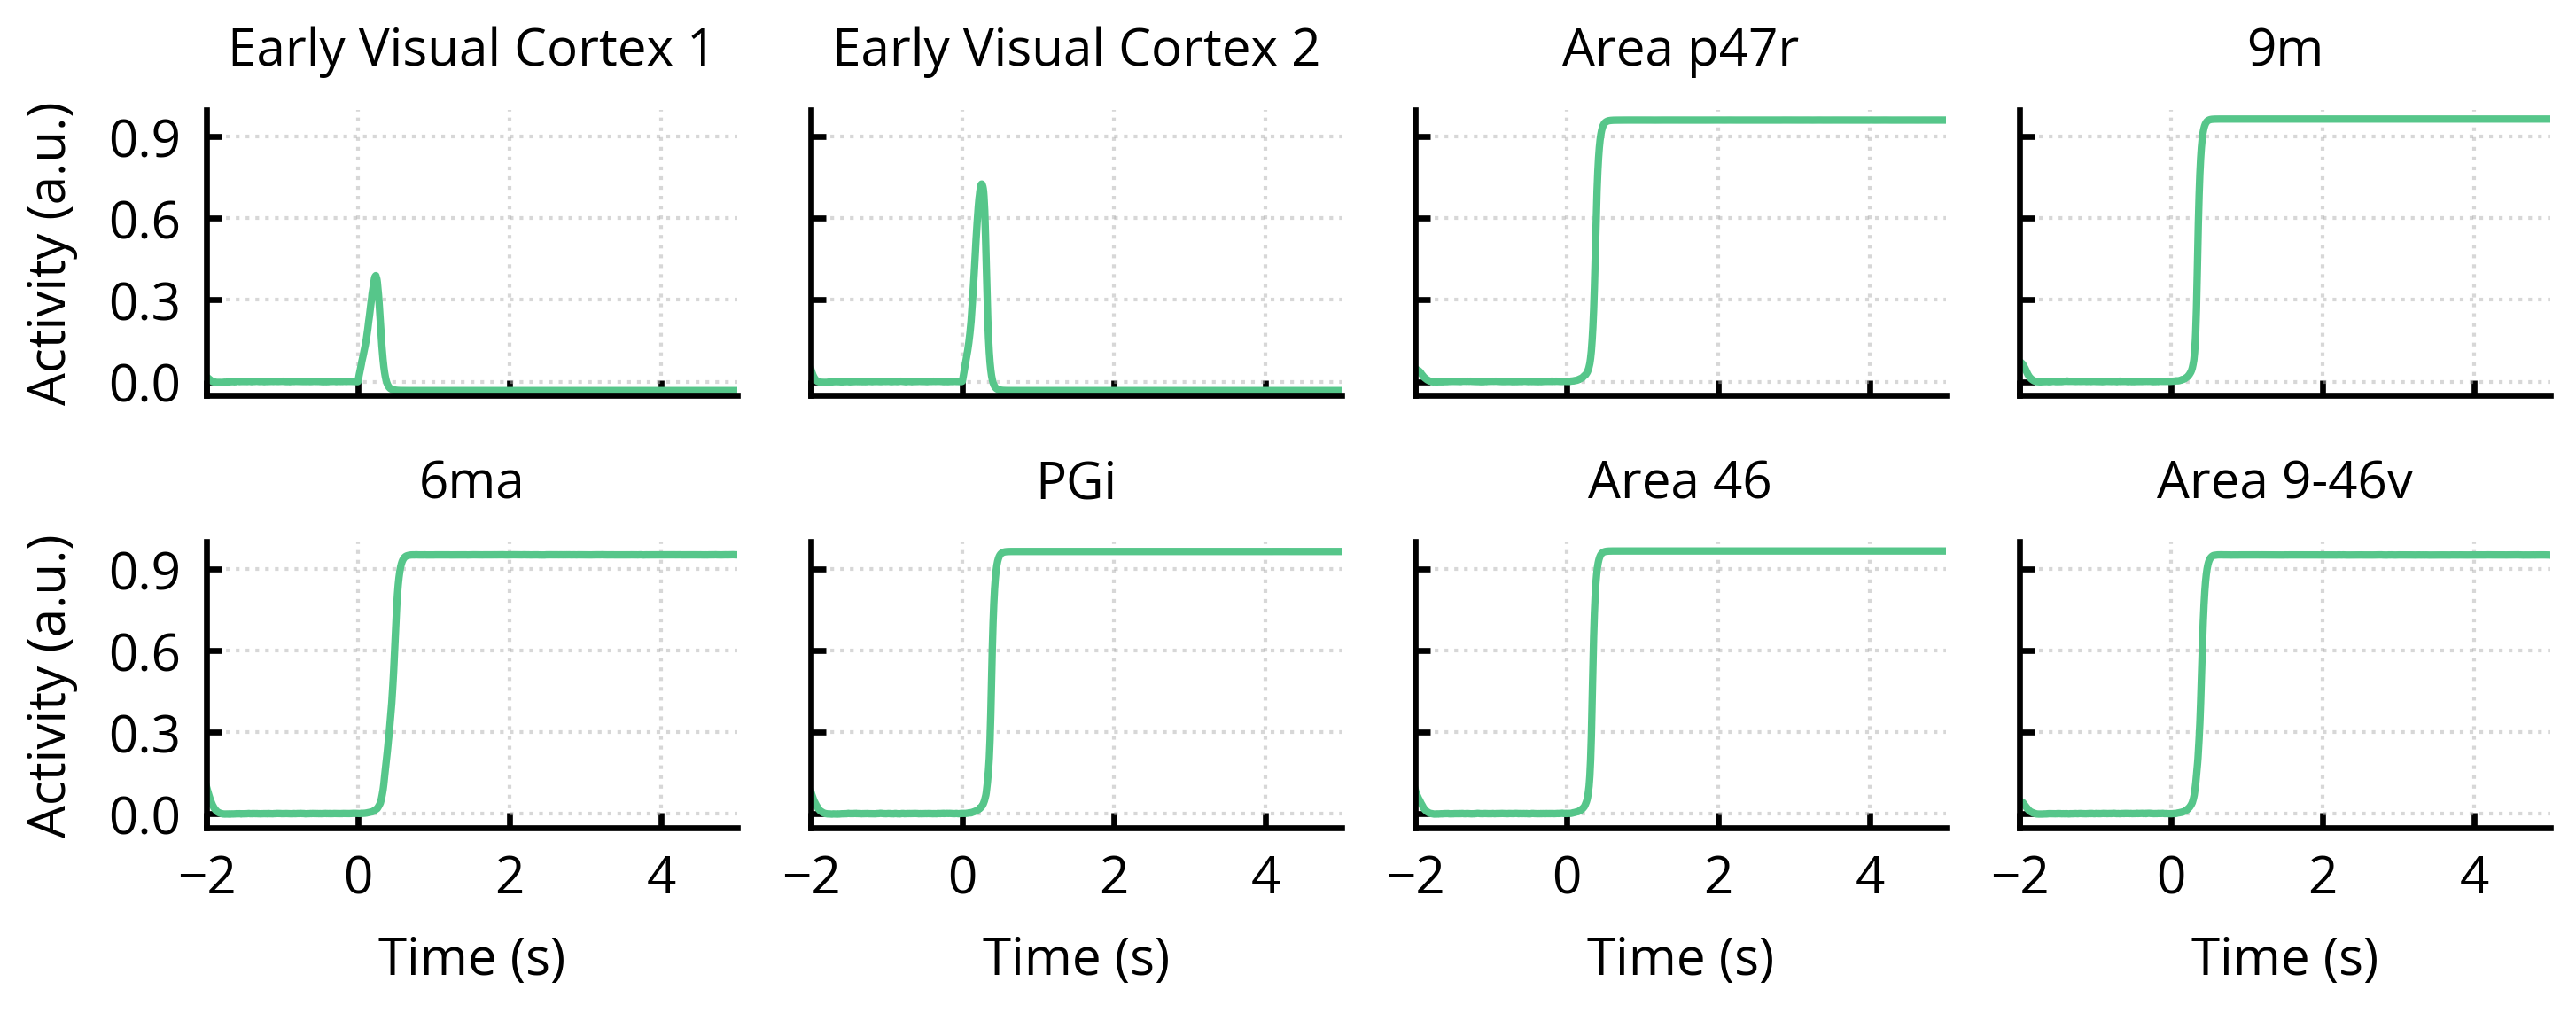

In [352]:
# Single 2x4 panel version of the plot_n_areas_wc figure above
# 2/3 of the 18.4 cm page width by 4.8 cm, Open Sans at 7 pt.
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Same style dict as the panel cell of ../Figure_3_DF.ipynb. Applied only inside the
# "with" block, so the rcParams that plot_n_areas_wc sets globally are left alone.
panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# plot_n_areas_wc was called with the default plot_I=False, so only the E population is drawn.
# Set plot_I = True to overlay the I population as in the (E, I) colour pair.
plot_I = False
pop_colors = ('#56c68a', '#eaa8b7')
downsample = 10

# Same time axis plot_n_areas_wc builds internally, shifted so the cue onset sits at 0
T = rE_store.shape[1]
t = (sim_time - store_time) + np.arange(T) * dt_store
t_down = t[::downsample] - stim_start_time

pops = [(rE_store, pop_colors[0])]
if plot_I:
    pops.append((rI_store, pop_colors[1]))

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 2 / 3 * 18.4 / CM
FIG_H = 4.8 / CM

with mpl.rc_context(panel_style):
    # every panel shares the time axis and the same y range, so only the bottom row
    # needs x tick labels and only the left column needs y tick labels
    fig, axes = plt.subplots(2, 4, figsize=(FIG_W, FIG_H), constrained_layout=True,
                             sharex=True, sharey=True)

    for i, (ax, area_name) in enumerate(zip(axes.flat, target_area_names)):
        area_idx = np.where(np.array(area_names) == area_name)[0][0]
        for store, color in pops:
            ax.plot(t_down, store[area_idx, ::downsample], color=color, linewidth=1)

        ax.set_title(area_names_for_figure[i])
        ax.set_xlim(-2, sim_time - 2)
        ax.set_ylim(-0.05, 1.0)   # same ylim as the plot_n_areas_wc call above

        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.grid(linestyle=':', alpha=0.5)

        # set_ticks_position turns the tick labels back on, undoing sharex/sharey,
        # so the inner tick labels have to be switched off again by hand
        ax.tick_params(labelbottom=(i >= 4), labelleft=(i % 4 == 0))

        # axis labels only on the outer panels, they would not fit on all eight
        if i % 4 == 0:
            ax.set_ylabel('Activity (a.u.)')  # WC rates are normalized, not Hz
        if i >= 4:
            ax.set_xlabel('Time (s)')

    # no bbox_inches='tight', so the file keeps the exact 12.27 x 4.8 cm size
    fig.savefig('plots/wc/persistent_activity_grid.svg')
    fig.savefig('plots/wc/persistent_activity_grid.pdf')
    plt.show()

In [353]:
# Script to plot brain maps during the cue and delay period under optimal parameters
# for model built with nmda PET imaging
import numpy as np
import matplotlib.pyplot as plt
from nibabel.freesurfer.io import read_annot
from nilearn import datasets, plotting
import nibabel.freesurfer as fs
import scienceplots
plt.style.use(['science', 'nature'])
from matplotlib.colors import LinearSegmentedColormap
plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)
cmaps = {
    "excitation_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#e7f6ed", "#86c3a2", "#56c68a"], N=256
    )
}

cue_FR = cue_fr

labels_schaefer, ctab_schaefer, region_names_schaefer = fs.read_annot('../../data/raw/brain_annotations/Schaefer/fsaverage5/atl-Schaefer2018_space-fsaverage5_hemi-L_desc-200Parcels7Networks_deterministic.annot')
region_names_schaefer = [r.decode('utf-8') for r in region_names_schaefer]
mapped_data_schaefer_cue = np.zeros_like(labels_schaefer, dtype=float) # Define a map with the same number of vertices as the annotation file
for i, region in enumerate(region_names_schaefer):
    region_idx = i
    if i == 0:
        mapped_data_schaefer_cue[labels_schaefer == region_idx] = None
    else:
        mapped_data_schaefer_cue[labels_schaefer == region_idx] = cue_FR[region_idx - 1] # First index in region_names is background
vmin, vmax = np.nanmin(mapped_data_schaefer_cue), np.nanmax(mapped_data_schaefer_cue)

fs = datasets.fetch_surf_fsaverage('fsaverage5')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_data_schaefer_cue, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps['excitation_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=0, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 150 if ext in ['png'] else None
        fig.savefig(f'plots/wc/cue_activity_{view}.{ext}', bbox_inches='tight')
    plt.close()
    
avg_FR_persistent = rE_avg_last_t_s
mapped_data_schaefer_persistent = np.zeros_like(labels_schaefer, dtype=float) # Define a map with the same number of vertices as the annotation file
for i, region in enumerate(region_names_schaefer):
    region_idx = i
    if i == 0:
        mapped_data_schaefer_persistent[labels_schaefer == region_idx] = None
    else:
        mapped_data_schaefer_persistent[labels_schaefer == region_idx] = avg_FR_persistent[region_idx - 1] # 
fsaverage = datasets.fetch_surf_fsaverage('fsaverage5') # Extract surface to plot on
vmin, vmax = np.nanmin(mapped_data_schaefer_persistent), np.nanmax(mapped_data_schaefer_persistent)

fs = datasets.fetch_surf_fsaverage('fsaverage5')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_data_schaefer_persistent, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps['excitation_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=0, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 150 if ext in ['png'] else None
        fig.savefig(f'plots/wc/persistent_activity_{view}.{ext}', bbox_inches='tight')
    plt.close()